In [20]:
#Biblioteki
import pandas as pd
import seaborn as sns

In [9]:
data = pd.read_csv('https://raw.githubusercontent.com/janszopa/ML_intro_24-25/refs/heads/main/data/Loan_Default.csv')

In [10]:
data.head()

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


In [15]:
rows = data.shape[0]
col = data.shape[1]
print(f'Wiersze: {rows}, Kolumny: {col}')

Wiersze: 148670, Kolumny: 34


In [16]:
data.describe()

,ID,year,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,property_value,income,Credit_Score,LTV,Status,dtir1
count,148670.000000,148670.0,1.486700e+05,112231.000000,112031.000000,109028.000000,148629.000000,1.335720e+05,139520.000000,148670.000000,133572.000000,148670.000000,124549.000000
mean,99224.500000,2019.0,3.311177e+05,4.045476,0.441656,3224.996127,335.136582,4.978935e+05,6957.338876,699.789103,72.746457,0.246445,37.732932
std,42917.476598,0.0,1.839093e+05,0.561391,0.513043,3251.121510,58.409084,3.599353e+05,6496.586382,115.875857,39.967603,0.430942,10.545435
min,24890.000000,2019.0,1.650000e+04,0.000000,-3.638000,0.000000,96.000000,8.000000e+03,0.000000,500.000000,0.967478,0.000000,5.000000
25%,62057.250000,2019.0,1.965000e+05,3.625000,0.076000,581.490000,360.000000,2.680000e+05,3720.000000,599.000000,60.474860,0.000000,31.000000
50%,99224.500000,2019.0,2.965000e+05,3.990000,0.390400,2596.450000,360.000000,4.180000e+05,5760.000000,699.000000,75.135870,0.000000,39.000000
75%,136391.750000,2019.0,4.365000e+05,4.375000,0.775400,4812.500000,360.000000,6.280000e+05,8520.000000,800.000000,86.184211,0.000000,45.000000
max,173559.000000,2019.0,3.576500e+06,8.000000,3.357000,60000.000000,360.000000,1.650800e+07,578580.000000,900.000000,7831.250000,1.000000,61.000000


In [21]:
# Winoski 
# year -> jedyna wartóść to 2019
# rate_of_interest min -> 0, dziwne?
# Interest_rate_spread wartosc min < 0, dziwne?
# Income min < 0
# Przy wykresach zwrocic uwage na atrybut term 

In [19]:
data.info()
print("\nBraki w danych:\n", data.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  object 
 3   Gender                     148670 non-null  object 
 4   approv_in_adv              147762 non-null  object 
 5   loan_type                  148670 non-null  object 
 6   loan_purpose               148536 non-null  object 
 7   Credit_Worthiness          148670 non-null  object 
 8   open_credit                148670 non-null  object 
 9   business_or_commercial     148670 non-null  object 
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            10

/Users/mikolajguzek-szopa/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


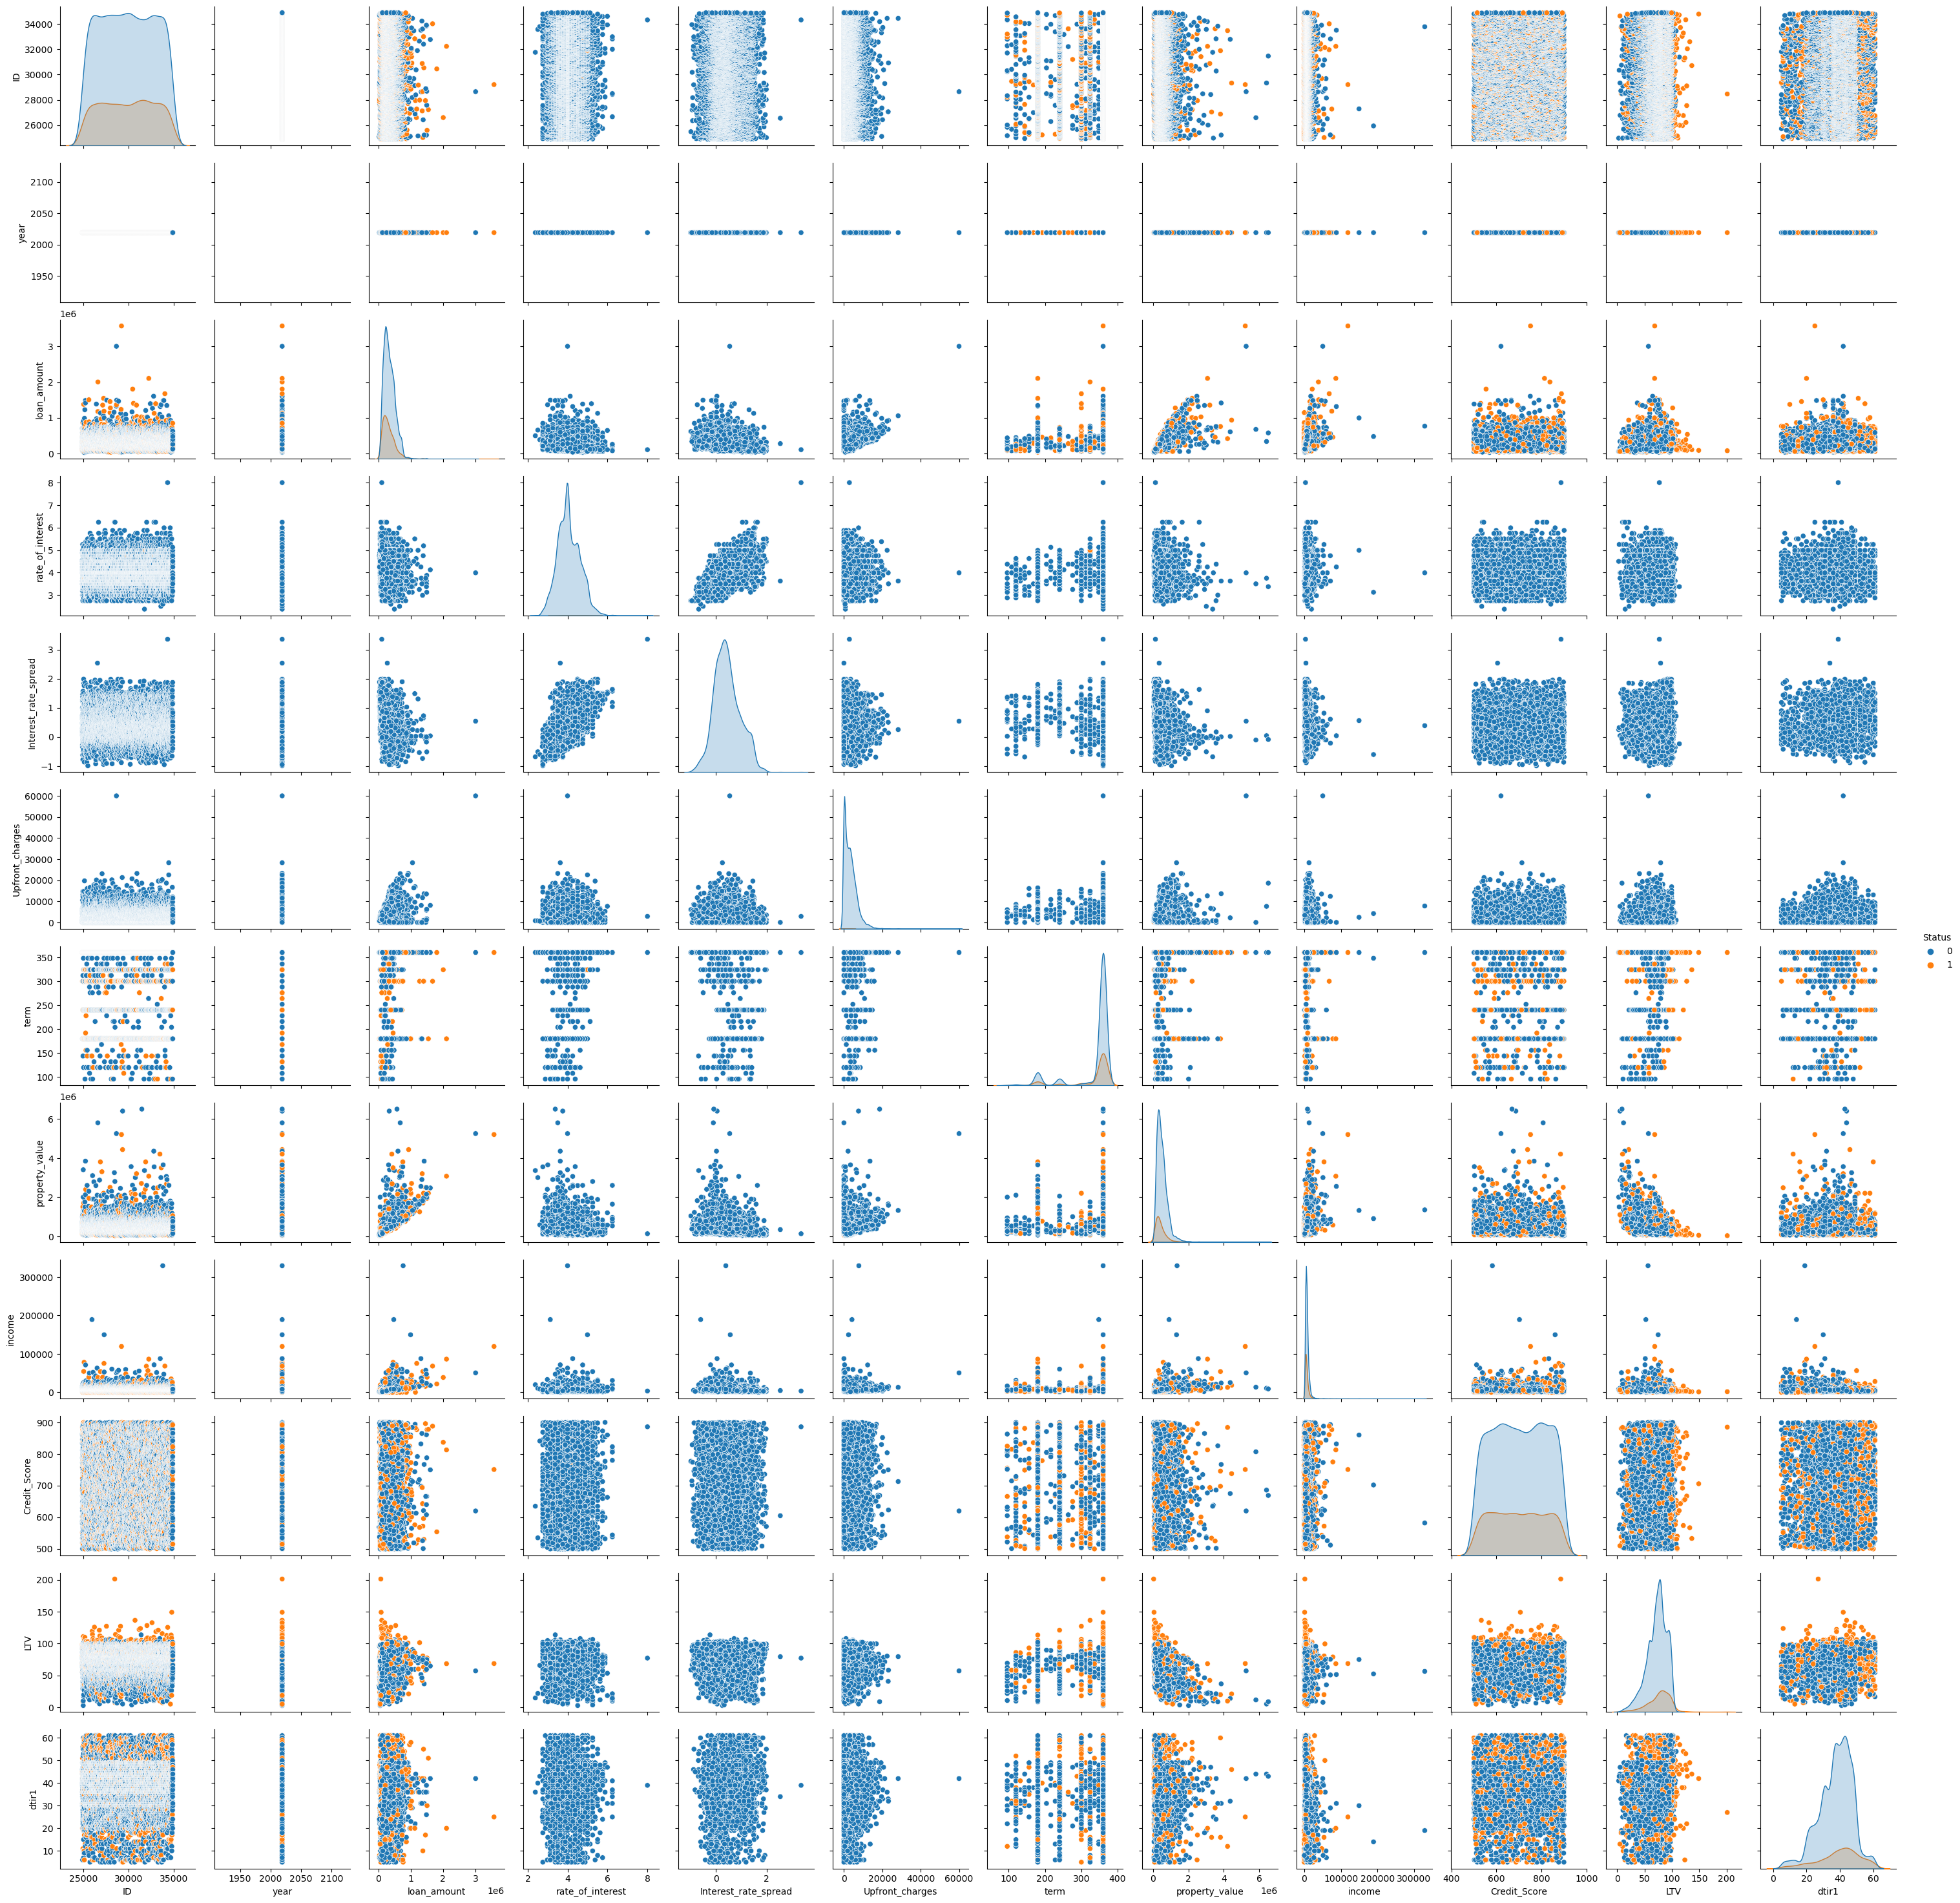

In [26]:
sns.pairplot(data[:10_000], hue='Status')


In [ ]:
# Winoski
# Credit_score wazne dla decyzji o kredycue(status)
# Im wyzsze Loan_amount tym więcej odmów kredytu(pomaranczowy kolor)


In [27]:
data['Status'].value_counts()

Status
0    112031
1     36639
Name: count, dtype: int64

In [ ]:
# Winoski
# Liczba wartości null w rate_of_interest, Interest_rate_spread, Upfront_charges jest bardzo podobna do liczby odmów kredytu

In [36]:
data.loc[data['Status'] == 1 & ~data['Interest_rate_spread'].isnull()]

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1


In [38]:
data1 = data.loc[data['Status'] == 1 & ~data['rate_of_interest'].isnull()]
data1['rate_of_interest']

266       3.750
706       4.625
1150      3.750
1219      4.500
3533      3.875
          ...  
145071    3.990
147037    4.875
147799    3.990
147974    3.750
148239    3.750
Name: rate_of_interest, Length: 200, dtype: float64

In [41]:
# Wnioski
# Osoby nie mające null w rate_of_interest i mające status 1, mają null w age i w submission_of_application
# moze to wynikać z błędów w danych
# 


<Axes: xlabel='Status', ylabel='LTV'>

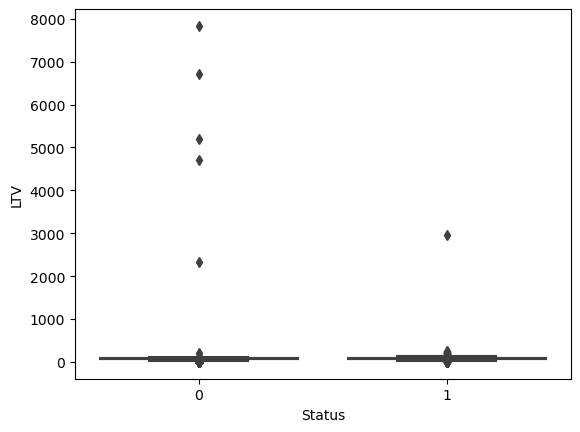

In [33]:
sns.boxplot(x = data['Status'],y = data['LTV'])

In [ ]:
# Winoski TODO
# Obiciac wartosci odstajace i wtedy porobic wykresy
# Sprawdzic korelacje miedzy danymi